# Segmentasi Pelanggan Bike Buyers: siapa yang harus ditarget?

**Pertanyaan bisnis:** tim pemasaran toko sepeda ingin memfokuskan kampanye. Pelanggan mana yang paling mungkin membeli sepeda, dan seberapa besar keuntungannya kalau kampanye hanya ditujukan ke kelompok itu?

**Pendekatan:**
1. Cari faktor yang **terbukti** berhubungan dengan keputusan membeli (uji chi-square + Cramér's V).
2. Buat segmen dari 3 faktor terkuat yang mudah dipakai tim pemasaran.
3. Buat **skor prospek** sederhana (0–4) dan hitung manfaat menargetkan skor tertinggi.
4. Buat profil segmen prioritas.

Data: 1.000 pelanggan (dataset Excel dari Alex The Analyst, sudah dibersihkan di Proyek 1).

## 1. Memuat data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", font_scale=0.95)
BIRU, ABU, MERAH = "#2b6cb0", "#b8b8b8", "#c05621"

df = pd.read_csv("data/bike_customers.csv")
df["beli"] = (df["purchased_bike"] == "Yes").astype(int)
RATA = df["beli"].mean()
print(df.shape, "| nilai kosong:", df.isna().sum().sum())
print(f"Tingkat pembelian keseluruhan: {RATA:.1%} ({df['beli'].sum()} dari {len(df)})")

(1000, 14) | nilai kosong: 0
Tingkat pembelian keseluruhan: 48.1% (481 dari 1000)


## 2. Faktor mana yang berhubungan dengan keputusan membeli?
Untuk setiap kolom kategori dipakai **uji chi-square**. Kalau p < 0,05, hubungannya kemungkinan bukan kebetulan.
**Cramér's V** (0–1) menunjukkan **seberapa kuat** hubungannya, sehingga faktor-faktor bisa dibandingkan.

           faktor  cramers_v p_value  signifikan
0    Jumlah mobil      0.226 2.2e-10        True
1   Kelompok umur      0.202 1.5e-09        True
2    Jarak tempuh      0.186 5.9e-07        True
3     Jumlah anak      0.179 5.8e-06        True
4      Pendidikan      0.159 4.3e-05        True
5          Region      0.117 1.0e-03        True
6  Status menikah      0.112 4.2e-04        True
7       Pekerjaan      0.089 9.1e-02       False
8          Gender      0.015 6.3e-01       False
9     Punya rumah      0.015 6.3e-01       False


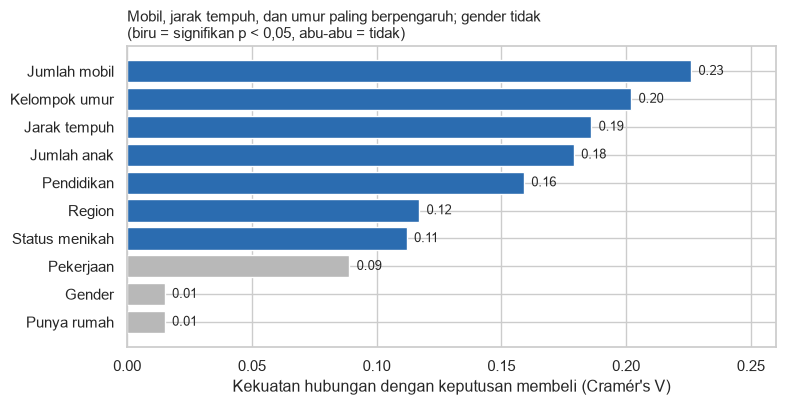

In [2]:
faktor = {"cars": "Jumlah mobil", "commute_distance": "Jarak tempuh", "age_bracket": "Kelompok umur",
          "children": "Jumlah anak", "education": "Pendidikan", "region": "Region",
          "marital_status": "Status menikah", "occupation": "Pekerjaan",
          "gender": "Gender", "home_owner": "Punya rumah"}
df["age_bracket"] = np.select([df["age"] > 54, df["age"] >= 31], ["Old", "Middle Age"], "Adolescent")

hasil = []
for kol, nama in faktor.items():
    tabel = pd.crosstab(df[kol], df["beli"])
    chi2, p, dof, _ = stats.chi2_contingency(tabel, correction=False)
    v = np.sqrt(chi2 / (len(df) * (min(tabel.shape) - 1)))
    hasil.append({"faktor": nama, "cramers_v": round(v, 3), "p_value": p, "signifikan": p < 0.05})
hasil = pd.DataFrame(hasil).sort_values("cramers_v", ascending=False).reset_index(drop=True)
print(hasil.to_string(formatters={"p_value": "{:.1e}".format}))

fig, ax = plt.subplots(figsize=(8, 4.2))
warna = [BIRU if s else ABU for s in hasil["signifikan"]]
ax.barh(hasil["faktor"], hasil["cramers_v"], color=warna)
ax.invert_yaxis()
for i, v in enumerate(hasil["cramers_v"]):
    ax.text(v + 0.003, i, f"{v:.2f}", va="center", fontsize=9)
ax.set_xlabel("Kekuatan hubungan dengan keputusan membeli (Cramér's V)")
ax.set_ylabel("")
ax.set_title("Mobil, jarak tempuh, dan umur paling berpengaruh; gender tidak\n(biru = signifikan p < 0,05, abu-abu = tidak)", loc="left", fontsize=11)
ax.set_xlim(0, 0.26)
plt.tight_layout()
plt.savefig("gambar/1_faktor.png", dpi=150)
plt.show()

**Hasil:**
- Tiga faktor terkuat: **jumlah mobil**, **jarak tempuh**, dan **kelompok umur**.
- Jumlah anak dan pendidikan juga signifikan. Tetapi jumlah anak sangat berkaitan dengan umur (korelasi 0,53, lihat Fase 5), dan keduanya lebih sulit dipakai untuk menarget iklan.
- **Gender, kepemilikan rumah, dan pekerjaan tidak terbukti berpengaruh.** Kampanye tidak perlu dibedakan berdasarkan gender.

## 3. Tingkat pembelian per faktor utama

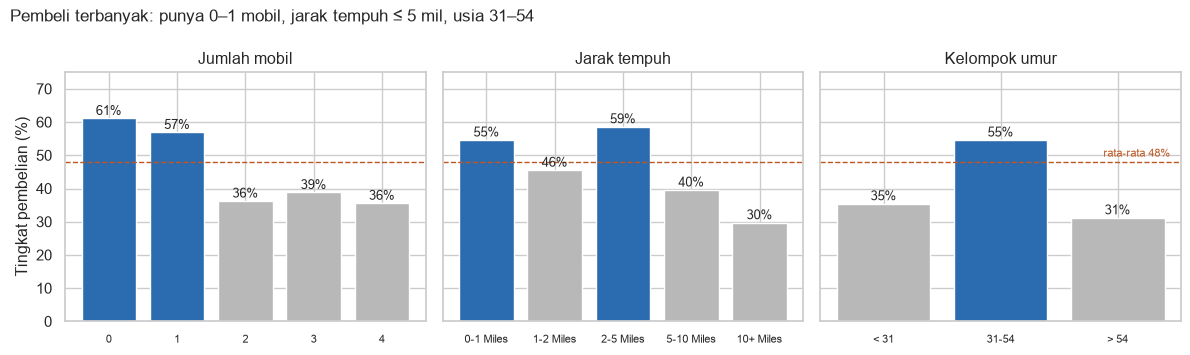

           jumlah  tingkat_beli
mobil                          
0-1 mobil     514         0.589
2+ mobil      486         0.366 

         jumlah  tingkat_beli
jarak                        
> 5 mil     303         0.360
≤ 5 mil     697         0.534 

          jumlah  tingkat_beli
umur                          
31-54 th     701         0.546
lainnya      299         0.328 



In [3]:
df["mobil"] = np.where(df["cars"] <= 1, "0-1 mobil", "2+ mobil")
df["jarak"] = np.where(df["commute_distance"].isin(["0-1 Miles", "1-2 Miles", "2-5 Miles"]), "≤ 5 mil", "> 5 mil")
df["umur"] = np.where(df["age"].between(31, 54), "31-54 th", "lainnya")

urutan = {"cars": [0, 1, 2, 3, 4],
          "commute_distance": ["0-1 Miles", "1-2 Miles", "2-5 Miles", "5-10 Miles", "10+ Miles"],
          "age_bracket": ["Adolescent", "Middle Age", "Old"]}
label = {"Adolescent": "< 31", "Middle Age": "31-54", "Old": "> 54"}
judul = {"cars": "Jumlah mobil", "commute_distance": "Jarak tempuh", "age_bracket": "Kelompok umur"}

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, (kol, urut) in zip(axes, urutan.items()):
    r = df.groupby(kol)["beli"].mean().reindex(urut) * 100
    ax.bar([label.get(x, str(x)) for x in r.index], r.values, color=[BIRU if v > RATA * 100 else ABU for v in r.values])
    ax.axhline(RATA * 100, color=MERAH, ls="--", lw=1)
    for i, v in enumerate(r.values):
        ax.text(i, v + 1, f"{v:.0f}%", ha="center", fontsize=9)
    ax.set_title(judul[kol])
    ax.set_xlabel("")
    ax.tick_params(axis="x", labelsize=8)
axes[0].set_ylabel("Tingkat pembelian (%)")
axes[0].set_ylim(0, 75)
axes[2].text(2.45, RATA * 100 + 1.5, f"rata-rata {RATA:.0%}", color=MERAH, fontsize=8, ha="right")
fig.suptitle("Pembeli terbanyak: punya 0–1 mobil, jarak tempuh ≤ 5 mil, usia 31–54", x=0.01, ha="left", fontsize=12)
plt.tight_layout()
plt.savefig("gambar/2_faktor_utama.png", dpi=150)
plt.show()

for kol in ["mobil", "jarak", "umur"]:
    print(df.groupby(kol)["beli"].agg(jumlah="count", tingkat_beli="mean").round(3), "\n")

Ketiga faktor diringkas menjadi dua kategori yang mudah dipakai tim pemasaran:
- **Mobil:** 0–1 mobil (58,9%) vs 2+ mobil (36,6%)
- **Jarak tempuh:** ≤ 5 mil (53,4%) vs > 5 mil (36,0%). Jarak 1–2 mil (46%) sedikit di bawah rata-rata, tetapi tetap jauh di atas jarak > 5 mil, jadi digabung ke kelompok ≤ 5 mil.
- **Umur:** 31–54 tahun (54,6%) vs lainnya (32,8%)

Batas 31–54 tahun sama dengan kelompok *Middle Age* di dashboard Excel/Power BI.

## 4. Segmentasi: 2 × 2 × 2 = 8 segmen

                           segmen  pelanggan  pembeli tingkat_beli porsi_pembeli         kelas
0  0-1 mobil · ≤ 5 mil · 31-54 th        361      241        66.8%         50.1%  A. Prioritas
1  0-1 mobil · > 5 mil · 31-54 th         44       21        47.7%          4.4%  B. Potensial
2   2+ mobil · > 5 mil · 31-54 th        110       50        45.5%         10.4%  B. Potensial
3   0-1 mobil · ≤ 5 mil · lainnya         79       35        44.3%          7.3%  B. Potensial
4   2+ mobil · ≤ 5 mil · 31-54 th        186       71        38.2%         14.8%  B. Potensial
5    2+ mobil · ≤ 5 mil · lainnya         71       25        35.2%          5.2%  B. Potensial
6    2+ mobil · > 5 mil · lainnya        119       32        26.9%          6.7%     C. Rendah
7   0-1 mobil · > 5 mil · lainnya         30        6        20.0%          1.2%     C. Rendah


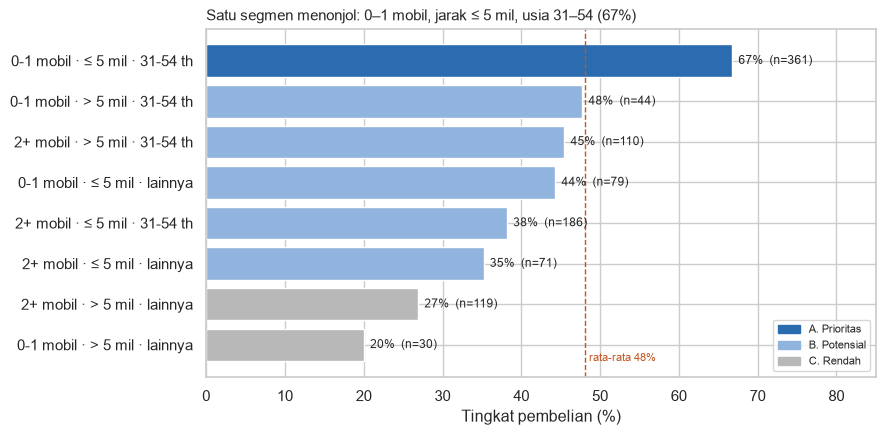

In [4]:
seg = (df.groupby(["mobil", "jarak", "umur"])["beli"]
         .agg(pelanggan="count", pembeli="sum", tingkat_beli="mean")
         .reset_index().sort_values("tingkat_beli", ascending=False).reset_index(drop=True))
seg["segmen"] = seg["mobil"] + " · " + seg["jarak"] + " · " + seg["umur"]

def tingkat(r):
    if r >= 0.6: return "A. Prioritas"
    if r >= 0.35: return "B. Potensial"
    return "C. Rendah"
seg["kelas"] = seg["tingkat_beli"].apply(tingkat)
seg["porsi_pembeli"] = seg["pembeli"] / df["beli"].sum()
print(seg[["segmen", "pelanggan", "pembeli", "tingkat_beli", "porsi_pembeli", "kelas"]]
      .to_string(formatters={"tingkat_beli": "{:.1%}".format, "porsi_pembeli": "{:.1%}".format}))

warna_kelas = {"A. Prioritas": BIRU, "B. Potensial": "#90b4dd", "C. Rendah": ABU}
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(seg["segmen"], seg["tingkat_beli"] * 100, color=seg["kelas"].map(warna_kelas))
ax.invert_yaxis()
ax.axvline(RATA * 100, color=MERAH, ls="--", lw=1)
ax.text(RATA * 100 + 0.5, 7.4, f"rata-rata {RATA:.0%}", color=MERAH, fontsize=8)
for i, r in seg.iterrows():
    ax.text(r["tingkat_beli"] * 100 + 0.8, i, f"{r['tingkat_beli']:.0%}  (n={r['pelanggan']})", va="center", fontsize=8.5)
ax.set_xlim(0, 85)
ax.set_xlabel("Tingkat pembelian (%)")
ax.set_title("Satu segmen menonjol: 0–1 mobil, jarak ≤ 5 mil, usia 31–54 (67%)", loc="left", fontsize=11)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=k) for k, c in warna_kelas.items()], loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig("gambar/3_segmen.png", dpi=150)
plt.show()

In [5]:
df = df.merge(seg[["mobil", "jarak", "umur", "kelas"]], on=["mobil", "jarak", "umur"])
kelas = df.groupby("kelas")["beli"].agg(pelanggan="count", pembeli="sum", tingkat_beli="mean")
kelas["porsi_pelanggan"] = kelas["pelanggan"] / len(df)
kelas["porsi_pembeli"] = kelas["pembeli"] / df["beli"].sum()
print(kelas.round(3))

# Apakah perbedaan Prioritas vs sisanya signifikan?
tabel = pd.crosstab(df["kelas"] == "A. Prioritas", df["beli"])
chi2, p, _, _ = stats.chi2_contingency(tabel)
print(f"\nPrioritas vs lainnya: chi2 = {chi2:.1f}, p = {p:.1e}")

              pelanggan  pembeli  tingkat_beli  porsi_pelanggan  porsi_pembeli
kelas                                                                         
A. Prioritas        361      241         0.668            0.361          0.501
B. Potensial        490      202         0.412            0.490          0.420
C. Rendah           149       38         0.255            0.149          0.079

Prioritas vs lainnya: chi2 = 77.6, p = 1.2e-18


**Hasil:**
- **Segmen A (Prioritas)**: 0–1 mobil, jarak tempuh ≤ 5 mil, usia 31–54. Isinya **36% pelanggan**, tetapi menyumbang **50% pembeli**, dengan tingkat pembelian **66,8%** (rata-rata 48,1%). Perbedaannya sangat signifikan (p ≈ 10⁻¹⁸).
- **Segmen C (Rendah)**: jarak > 5 mil dan usia di luar 31–54. Tingkat pembeliannya hanya 20–27%.
- Sisanya (B) mendekati atau sedikit di bawah rata-rata.

## 5. Skor prospek (0–4) dan manfaat penargetan
Segmen di atas memakai aturan "semua syarat harus terpenuhi". Cara lain yang lebih fleksibel: beri **1 poin** untuk setiap ciri positif, lalu urutkan pelanggan berdasarkan skornya.
Ciri positif: 0–1 mobil · jarak ≤ 5 mil · usia 31–54 · lajang (*Single*, juga signifikan di Fase 5).

      pelanggan  pembeli  tingkat_beli  kum_pelanggan  kum_pembeli  \
skor                                                                 
4           162      116         0.716            162          116   
3           360      202         0.561            522          318   
2           235       90         0.383            757          408   
1           176       58         0.330            933          466   
0            67       15         0.224           1000          481   

      tingkat_beli_kum  porsi_pembeli_kum  
skor                                       
4                0.716              0.241  
3                0.609              0.661  
2                0.539              0.848  
1                0.499              0.969  
0                0.481              1.000  


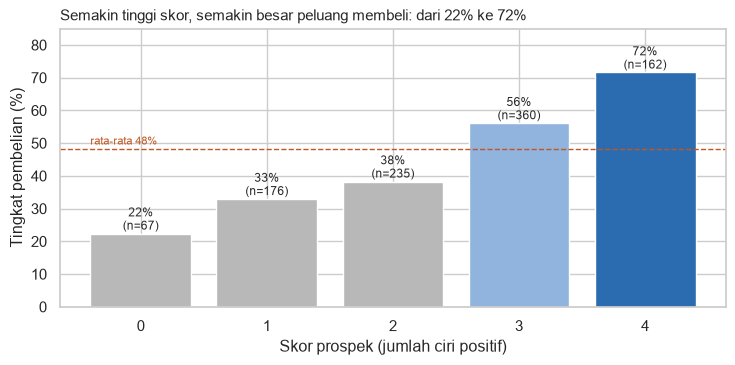

In [6]:
df["skor"] = ((df["mobil"] == "0-1 mobil").astype(int) + (df["jarak"] == "≤ 5 mil").astype(int)
              + (df["umur"] == "31-54 th").astype(int) + (df["marital_status"] == "Single").astype(int))
skor = df.groupby("skor")["beli"].agg(pelanggan="count", pembeli="sum", tingkat_beli="mean")

target = skor.sort_index(ascending=False)
target["kum_pelanggan"] = target["pelanggan"].cumsum()
target["kum_pembeli"] = target["pembeli"].cumsum()
target["tingkat_beli_kum"] = target["kum_pembeli"] / target["kum_pelanggan"]
target["porsi_pembeli_kum"] = target["kum_pembeli"] / df["beli"].sum()
print(target.round(3))

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.bar(skor.index.astype(str), skor["tingkat_beli"] * 100,
       color=[ABU, ABU, ABU, "#90b4dd", BIRU])
ax.axhline(RATA * 100, color=MERAH, ls="--", lw=1)
ax.text(-0.4, RATA * 100 + 1.5, f"rata-rata {RATA:.0%}", color=MERAH, fontsize=8)
for i, r in skor.reset_index().iterrows():
    ax.text(i, r["tingkat_beli"] * 100 + 1.2, f"{r['tingkat_beli']:.0%}\n(n={int(r['pelanggan'])})", ha="center", fontsize=8.5)
ax.set_ylim(0, 85)
ax.set_xlabel("Skor prospek (jumlah ciri positif)")
ax.set_ylabel("Tingkat pembelian (%)")
ax.set_title("Semakin tinggi skor, semakin besar peluang membeli: dari 22% ke 72%", loc="left", fontsize=11)
plt.tight_layout()
plt.savefig("gambar/4_skor.png", dpi=150)
plt.show()

**Cara membaca tabel kumulatif:**
- Kalau kampanye hanya ditujukan ke pelanggan **skor 4** (16% pelanggan), tingkat pembeliannya **71,6%**, hampir 1,5 kali rata-rata.
- Kalau ditujukan ke **skor 3–4** (52% pelanggan), tingkat pembeliannya **60,9%**, dan kelompok ini mencakup **66% dari seluruh pembeli**.
- Artinya: dengan menjangkau separuh pelanggan saja, tim pemasaran tetap menjangkau dua pertiga calon pembeli, dengan biaya kampanye sekitar separuhnya.

## 6. Profil segmen Prioritas vs lainnya

In [7]:
df["prioritas"] = np.where(df["kelas"] == "A. Prioritas", "Prioritas", "Lainnya")
profil = df.groupby("prioritas").agg(
    pelanggan=("id", "count"),
    rata_income=("income", "mean"),
    rata_umur=("age", "mean"),
    rata_anak=("children", "mean"),
    persen_lajang=("marital_status", lambda s: (s == "Single").mean() * 100),
    persen_sarjana=("education", lambda s: s.isin(["Bachelors", "Graduate Degree"]).mean() * 100),
).round(1)
print(profil.T)
print()
print((pd.crosstab(df["region"], df["prioritas"], normalize="columns") * 100).round(1))
print()
print((df[df["prioritas"] == "Prioritas"].groupby("region")["beli"].mean() * 100).round(1))

prioritas       Lainnya  Prioritas
pelanggan         639.0      361.0
rata_income     60062.6    49806.1
rata_umur          46.3       40.3
rata_anak           2.1        1.5
persen_lajang      46.9       44.9
persen_sarjana     36.6       68.1

prioritas      Lainnya  Prioritas
region                           
Europe            21.8       44.6
North America     53.4       46.3
Pacific           24.9        9.1

region
Europe           65.8
North America    62.9
Pacific          90.9
Name: beli, dtype: float64


**Profil segmen Prioritas** (dibandingkan pelanggan lainnya):
- **Lebih berpendidikan:** 68% sarjana (S1/S2), dibandingkan 37% pada pelanggan lainnya.
- **Income lebih rendah:** rata-rata $49.806 vs $60.063. Ini cocok dengan temuan Fase 5 bahwa income bukan penentu keputusan membeli. Kemungkinan sepeda dipakai sebagai **alat transportasi hemat** untuk jarak dekat, bukan barang mewah.
- **Lebih muda dan anaknya lebih sedikit:** rata-rata 40 tahun dan 1,5 anak (lainnya 46 tahun dan 2,1 anak).
- **Lokasi:** 45% di Europe dan 46% di North America, hanya 9% di Pacific. Tetapi 33 pelanggan Prioritas di Pacific membeli hampir semuanya (91%).
- Pesan kampanye yang cocok: *"sepeda untuk ke kantor/kampus, hemat dan sehat"*.

## 7. Kesimpulan & rekomendasi
1. **Targetkan segmen Prioritas** (0–1 mobil, jarak ≤ 5 mil, usia 31–54): 36% pelanggan yang menyumbang 50% pembeli, dengan tingkat pembelian 67%.
2. **Pakai skor prospek** untuk daftar kampanye: skor 3–4 menjangkau 66% calon pembeli dengan setengah jumlah kontak.
3. **Jangan membedakan kampanye berdasarkan gender atau kepemilikan rumah.** Keduanya tidak berpengaruh.
4. Untuk pelanggan dengan jarak > 5 mil, sepeda biasa kurang menarik. Pertimbangkan produk lain, misalnya **sepeda listrik**, lalu uji dengan kampanye kecil terlebih dahulu.

**Keterbatasan:**
- Data latihan, 1.000 pelanggan, satu periode waktu.
- Hubungan ini **bukan sebab-akibat**: tidak punya mobil tidak *menyebabkan* orang membeli sepeda.
- Segmentasi dibuat dengan aturan sederhana (*rule-based*). Langkah lanjut: membandingkan hasilnya dengan metode *clustering* seperti K-Means, atau model prediksi seperti regresi logistik.